In [ ]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import matplotlib.pyplot as plt
from IPython import display
import seaborn as sns

import time
import numpy as np

from scipy.stats import norm, multivariate_normal
from scipy.optimize import brentq

from scipy import stats
import rearrangement_algorithm as ra

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


**Case 1**: A bivariate distribution with Gaussian Marginals and varying linear correlation coefficient $\rho$. The dependence structure here is a Gaussian Copula.

The VaR is defined on the lower tail of the distributions given by:
$$\mathrm{VaR}_{\alpha}(Z)=F_{Z}^{-1}(1-\alpha) = \sup\{z\in\mathbb{R}: \mathbb{P}(Z > z) \geq \alpha\}$$


Let $d=2$ and $a=(1,1)$, and marginals $X_{1}\sim N(\mu_{1},\sigma_{1}^{2})$ and $X_{2}\sim N(\mu_{2},\sigma_{2}^{2})$.
Dependence structure is a Gaussian Copula $C^{\mathrm{Ga}}_{\rho}$, $\rho\in[-1,1]$, so that $(X_{1},X_{2})^{\top}$ is bivariate normal.

Then, a linear sum of components Z given by:
$$
Z=X_{1}+X_{2}\sim N\big(\mu_{Z},\,\sigma_{Z}^{2}(\rho)\big)
$$
The VaR order holds strictly w.r.t correlation $\rho$ only if Z is normal.

In [41]:
d = 2
a = np.array([1, 1])
mu1 = 10; mu2 = 15; s1 = 2; s2 = 4
alpha = 0.9

def check_VaR(rho):
    mu = np.array([mu1, mu2])
    cov = np.array([[s1**2, rho*s1*s2],
                    [rho*s1*s2, s2**2]])
    X = multivariate_normal(mean = mu, cov = cov) #Bivariate X

    # Linear sum of X given by Z
    mu_Z = a @ mu #np.sum(mu)
    v_Z = a @ cov @ a #np.sum(cov) # a^T.E.a
    Z = norm(loc = mu_Z, scale = np.sqrt(v_Z))

    # Find the VaR for Z on the lower tail at different rho values
    VaR_Z = mu_Z + norm.ppf(1-alpha) * np.sqrt(v_Z)
    return VaR_Z

print('Comparing the VaR for varying rho = [-1, 1]')
rhos = np.array([-0.9999999, 0, 0.5, 0.9999999])

vars_Z = np.array([check_VaR(rho) for rho in rhos])
for rho, v in zip(rhos, vars_Z): print(f'rho = {rho:+.2f}  VaR = {v:.3f}')

# spread of VaR between rho = -1 and rho = 1
spread_VaR = 2 * min(a[0]*s1, a[1]*s2) * norm.ppf(alpha)
print(f'VaR[rho = -1] - VaR[rho = 1] = {spread_VaR:.2f} check {vars_Z[0]- vars_Z[3]:.3f}')

Comparing the VaR for varying rho = [-1, 1]
rho = -1.00  VaR = 22.437
rho = +0.00  VaR = 19.269
rho = +0.50  VaR = 18.219
rho = +1.00  VaR = 17.311
VaR[rho = -1] - VaR[rho = 1] = 5.13 check 5.126


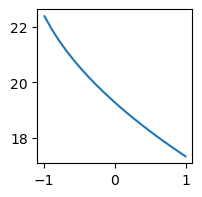

In [42]:
rhos = np.linspace(-0.99, 0.99, 20)
vars_Z = np.array([check_VaR(rho) for rho in rhos])
plt.figure(figsize=(2,2))
plt.plot(rhos, vars_Z)

For all $\alpha \geq 0.5$, the VaR is strictly decreasing with increasing correlation coefficient $\rho$
$$
\mathrm{VaR}^{W}_{\alpha}(Z)>\mathrm{VaR}^{\Pi}_{\alpha}(Z)>\mathrm{VaR}^{M}_{\alpha}(Z),
$$

Useful conditions: At $\rho = 1$, the VaR of Z is sum of VaR of marginals X1 & X2.

Defining
$\underline{\mathrm{VaR}}_{\alpha}(Z)$ as **worst case VaR** (minimum) and $\overline{\mathrm{VaR}}_{\alpha}(Z)$ as **best case VaR** (maximum), the interval $[\mathrm{VaR}^{M}_{\alpha},\mathrm{VaR}^{W}_{\alpha}]$ falls between these extremes.

At $\rho = -1$, the $\mathrm{VaR}_{\alpha}(Z)=\mu_{Z}+\Phi^{-1}(1-\alpha)\,\sigma_{Z}(\rho)$, here $\sigma_{Z}(-1)$ is $|\rho_{1} - \rho_{2}|$, if X1 and X2 has identical variance, the upper end $\mathrm{VaR}^{W}_{\alpha}(Z)$ is sharp i.e $\mathrm{VaR}^{W}_{\alpha} = \overline{\mathrm{VaR}}_{\alpha}(Z)$.

Comonotonicity always maximises Var(Z), but maximising variance only minimises VaR when the shape of Z is held fixed (normal).

**Case 2**: Bivariate distribution with Gaussian Marginals (same type) and Z = X1 + X2, but considering non-gaussian dependence structure given by \
$\rho=\lambda\rho_{1}+(1-\lambda)\rho_{2}$ with  $\rho_{1}<\rho<\rho_{2}$ and $\lambda\in(0,1)$ (Gaussian Mixuture model if Xi are gaussian.)

$F=\lambda F_{\rho_{1}}+(1-\lambda)F_{\rho_{2}},$ is the cdf.

Applying this dependence to X,
$$
F_{X_{i}}(x) =\lambda\,\Phi\!\Big(\tfrac{x-\mu_{i}}{\sigma_{i}}\Big) +(1-\lambda)\,\Phi\!\Big(\tfrac{x-\mu_{i}}{\sigma_{i}}\Big) \text{such that}  F\in\mathcal{F}(F_{1},F_{2})
$$

To get $\mathrm{VaR}_{\alpha}(Z)$ under this mixture dependence $F$, use `brentq()` to solve for $\alpha > 0.5$ given by
$$
\mathrm{VaR}_{\alpha}(Z)=\texttt{brentq}\big(F_{Z}(x)-(1-\alpha),\ \text{low},\ \text{high}\big),
$$
where if $\rho_2 > \rho_1$
$$
(1-\lambda)\,\Phi\!\Big(\tfrac{x-\mu_{Z}}{\sigma_{Z}(\rho_{2})}\Big)\;\leq\;F_{Z}(x)\;\leq\;
\Phi\!\Big(\tfrac{x-\mu_{Z}}{\sigma_{Z}(\rho_{2})}\Big), \
$$
$$
\text{low}=\mu_{Z}+\sigma_{Z}(\rho_{2})\,\Phi^{-1}(1-\alpha),
\qquad
\text{high}=\mu_{Z}+\sigma_{Z}(\rho_{2})\,\Phi^{-1}\!\Big(\tfrac{1-\alpha}{1-\lambda}\Big).
$$
The widest component $\sigma_{Z}(\rho_{2})$ sets both ends because it dominates the lower tail.



In [43]:
# 1. marginals, weights, and sigma_Z(rho) with the weights baked in
d = 2
a = np.array([1, 1])
mu1 = 10; mu2 = 15; s1 = 2; s2 = 4
alpha = 0.9

# Z with Gaussian copula C^Ga_rho
mu = np.array([mu1, mu2]); mu_Z = a @ mu
sig_Z = lambda rho: np.sqrt(a[0]**2*s1**2 + a[1]**2*s2**2 + 2*rho*a[0]*a[1]*s1*s2) # sqrt(a^T.E.a)
VaR_G = lambda rho, al = alpha: mu_Z + norm.ppf(1 - al) * sig_Z(rho) # VaR as fn of rho and alpha

# Z with new dependence structure: F is a mixture of two Gaussian copulas
rho1 = 0.2; rho2 = 0.8; lam = 0.5  ; rho_m = lam*rho1 + (1 - lam)*rho2

cdf_F = lambda x: lam * norm.cdf(x, mu_Z, sig_Z(rho1)) + (1 - lam) * norm.cdf(x, mu_Z, sig_Z(rho2))

# finding the VaR using brentq
s_mx, w = (sig_Z(rho1), lam) if sig_Z(rho1) > sig_Z(rho2) else (sig_Z(rho2), 1 - lam) #widest component and its weight (rho, lambda)
low  = lambda al: mu_Z + s_mx * norm.ppf(1 - al)          #F_Z(low) <= 1-al
high = lambda al: mu_Z + s_mx * norm.ppf((1 - al)/w)      #F_Z(high) >= 1-al
func = lambda x, al: cdf_F(x) - (1 - al)                  # function

VaR_F = lambda al = alpha: brentq(func, low(al), high(al), args = (al,)) # VaR_Z with F dependence

This case, for the same correlation $\rho$ and same marginals, comparing the $\mathrm{VaR}_{\alpha}(Z)$ with the Gaussian vs Mixture dependence. \
above - exact formula
below - empirical check (eg m.6 kirankarra)

In [44]:
rng = np.random.default_rng(0); n = 500

def u_gauss(rho, n = n, rng = rng): #Gaussian copula, returns U in [0,1]^d
    A = np.linalg.cholesky([[1, rho], [rho, 1]]) # A = transform using Cholesky factor
    return norm.cdf(rng.standard_normal((n, d)) @ A.T) # cdf(Z-samples(n,d)~N(0,1) @ A)

def u_mix(rho1 = rho1, rho2 = rho2, lam = lam, n = n, rng = rng): # Mixture model U in[0,1]^d space
    k = rng.random(n) < lam
    return np.where(k[:,None], u_gauss(rho1, n, rng), u_gauss(rho2, n, rng)) # pick A, when k<lam or pick B when k>lam

F_inv = [lambda u: norm.ppf(u, mu1, s1), lambda u: norm.ppf(u, mu2, s2)] #define cdf F^-1 for Xi
X_of = lambda U: np.column_stack([f(U[:,j]) for j, f in enumerate(F_inv)]) # Sklar's theorem X=F^-1(U) (transform U to X)
# Z_of = lambda U: X_of(U) @ a #Z = matmul(X, a)

U_G = u_gauss(rho_m); U_F = u_mix()          #one draw per copula
X_G = X_of(U_G);      X_F = X_of(U_F)        #applying marginals to get the bivariate X
Z_G = X_G @ a;        Z_F = X_F @ a          #calculate Z from X

In [45]:
print('rho  ', np.corrcoef(X_G.T)[0,1], np.corrcoef(X_F.T)[0,1], ' target', rho_m, 'rho of G and F (empirical) are similar')
print('sd Z_G=', Z_G.std(), ';sd Z_G=', Z_F.std(), ';sig_Z(rho)=', sig_Z(rho_m), 'std() of empirical G, F and exact Z') 
print(f'VaR C^Ga  Empirical {np.quantile(Z_G, 1-alpha):8.3f}  exact {VaR_G(rho_m):8.3f}')
print(f'VaR F     Empirical {np.quantile(Z_F, 1-alpha):8.3f}  exact {VaR_F():8.3f}')

print('\nratio -> sig_Z(rho2)/sig_Z(rho) =', sig_Z(rho2)/sig_Z(rho_m))

print(f'alpha = {alpha} VaR_F {VaR_F(alpha):0.3f}  VaR_Grho {VaR_G(rho_m, alpha):0.3f} VaR_Grho2 {VaR_G(rho2, alpha):0.3f}  ratio {(VaR_F(alpha) - mu_Z)/(VaR_G(rho_m, alpha) - mu_Z):.4f}')


rho   0.5107119753160161 0.41750310294154586  target 0.5 rho of G and F (empirical) are similar
sd Z_G= 5.187311490701057 ;sd Z_G= 5.017067274698667 ;sig_Z(rho)= 5.291502622129181 std() of empirical G, F and exact Z
VaR C^Ga  Empirical   17.786  exact   18.219
VaR F     Empirical   18.392  exact   18.253

ratio -> sig_Z(rho2)/sig_Z(rho) = 1.082325538564332
alpha = 0.9 VaR_F 18.253  VaR_Grho 18.219 VaR_Grho2 17.660  ratio 0.9950


Worst VaR of Mixture model below comonotonicity 0 of 3249  gap range 0.0001506557764692218 0.9199589980099852


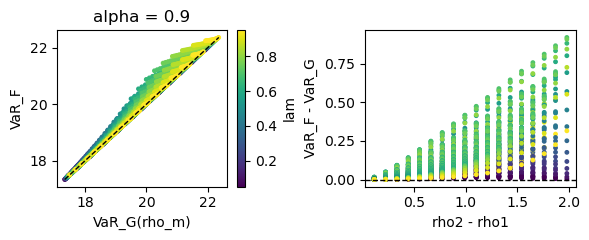

In [46]:
def VaR_F_of(rho1, rho2, lam, al = alpha):
    cdf = lambda x: lam*norm.cdf(x, mu_Z, sig_Z(rho1)) + (1 - lam)*norm.cdf(x, mu_Z, sig_Z(rho2))
    s_mx, w = (sig_Z(rho1), lam) if sig_Z(rho1) > sig_Z(rho2) else (sig_Z(rho2), 1 - lam)
    lo = mu_Z + s_mx*norm.ppf(1 - al) - 1e-6*s_mx
    hi = mu_Z + s_mx*norm.ppf(min(1 - 1e-15, (1 - al)/w)) + 1e-6*s_mx
    return brentq(lambda x: cdf(x) - (1 - al), lo, hi)
alpha = 0.9
grid = np.arange(-0.99, 1.0, 0.11); lams = np.arange(0.05, 1.0, 0.05)
R = np.array([(r1, r2, l, VaR_F_of(r1, r2, l), VaR_G(l*r1 + (1-l)*r2)) for r1 in grid for r2 in grid if r1 < r2 for l in lams])
print('Worst VaR of Mixture model below comonotonicity', (R[:,3] < R[:,4]).sum(), 'of', len(R), ' gap range', (R[:,3]-R[:,4]).min(), (R[:,3]-R[:,4]).max())

fig, ax = plt.subplots(1, 2, figsize = (6,2.5))
sc = ax[0].scatter(R[:,4], R[:,3], c = R[:,2], s = 6, cmap = 'viridis')
lim = [R[:,3:].min(), R[:,3:].max()]; ax[0].plot(lim, lim, 'k--', lw = 1) #y = x
ax[0].set(xlabel = 'VaR_G(rho_m)', ylabel = 'VaR_F', title = f'alpha = {alpha}')
plt.colorbar(sc, ax = ax[0], label = 'lam')

ax[1].scatter(R[:,1] - R[:,0], R[:,3] - R[:,4], c = R[:,2], s = 6, cmap = 'viridis')
ax[1].axhline(0, color = 'k', ls = '--', lw = 1)
ax[1].set(xlabel = 'rho2 - rho1', ylabel = 'VaR_F - VaR_G')
plt.tight_layout()


In [47]:
# finding alpha* beyond which VaR of GM is worse than VaR of Gaussian Z at corr rho_m
g = lambda t: lam*norm.cdf(t/sig_Z(rho1)) + (1-lam)*norm.cdf(t/sig_Z(rho2)) - norm.cdf(t/sig_Z(rho_m))
t_star = brentq(g, -30, -0.1)        # bracket away from t=0
alpha_star = 1 - norm.cdf(t_star/sig_Z(rho_m)); print('alpha* ', alpha_star)

alpha*  0.9576011397948917


To find worst-case $\underline{\mathrm{VaR}}_{\alpha}(Z)$ over all possible joint distributions of X given by the Frechet class:

It is the lower bound of $\epsilon=0.1$-quantile (P90) of the linear sum: 
$$\underline{\mathrm{VaR}}_{\alpha}(Z)=\sup_{\substack{a>0}}\big\{F_1^{-1}(a)+F_2^{-1}(\epsilon - a)\big\}.$$
Since, the marginals are gaussian, it can be solved to find the combination of X1 and X2 (split by a) that gives the maximum sum.


In [48]:
from scipy.optimize import minimize_scalar
eps = 1 - alpha # 10th percentile of Z

def h(a):
    return norm.ppf(a, mu1, s1) + norm.ppf(eps - a, mu2, s2)

res = minimize_scalar(lambda a: -h(a), bounds=(1e-12, eps-1e-12), method='bounded', options={'xatol':1e-14})
underline = -res.fun; print('_VaR_*', underline, 'at a*=', res.x)

_VaR_* 15.335317693839915 at a*= 0.029653517064960944


To find best-case $\overline{\mathrm{VaR}}_{\alpha}(Z)$ over all possible joint distributions of X given by the Frechet class:

It is the upper bound of $\eta=0.1$-quantile (P90) of the linear sum:
$$\overline{\mathrm{VaR}}_{\alpha}(Z)=\inf_{\substack{\epsilon\le a<1}}\big\{F_1^{-1}(a)+F_2^{-1}(1+\epsilon-a)\big\}.$$
Since, the marginals are gaussian, it can be solved to find the combination of X1 and X2 (split by a) that gives the maximum sum.


In [49]:
from scipy.optimize import minimize_scalar
eps = 1 - alpha # 10th percentile of Z

def h(a):
    return norm.ppf(a, mu1, s1) + norm.ppf(1 + eps - a, mu2, s2)

res = minimize_scalar(lambda a: h(a), bounds=(eps, 1), method='bounded', options={'xatol':1e-14})
underline = res.fun; print('-VaR-*', underline, 'at a*=', res.x)

-VaR-* 24.131300716264242 at a*= 0.9375876963623803


So far for $\alpha>\tfrac12$, with $\alpha = 0.9$ and $0<\rho_{1}<\rho<\rho_{2}\le1$,
$$X_1\sim N(10,2^2),\qquad X_2\sim N(15,4^2), \qquad Z = X_1 + X_2$$

$$
\begin{aligned}
\underline{\mathrm{VaR}}_{\alpha}(Z)
\le\mathrm{VaR}^{M}_{\alpha}(Z)
<\mathrm{VaR}_{\alpha,F}(Z)\nonumber
<\mathrm{VaR}_{\alpha,F_{\rho}}(Z)
<\mathrm{VaR}^{\Pi}_{\alpha}(Z)
<\mathrm{VaR}^{W}_{\alpha}(Z)
\le\overline{\mathrm{VaR}}_{\alpha}(Z),
\end{aligned}
$$
$$
\mathbf{15.335} \le 17.311 < 18.219 (\rho = 0.5) < 18.253 (\text{GM}) < 19.269 < 22.437 \le 24.1313,
$$



Using the rearrangement-algorithm package to find worst $\underline{\mathrm{VaR}}_{\alpha}(Z)$ and best $\underline{\mathrm{VaR}}_{\alpha}(Z)$ for both cases

In [50]:
mu1 = 10; mu2 = 15; s1 = 2; s2 = 4; alpha = 0.9
qf = [stats.norm(mu1, s1).ppf, stats.norm(mu2, s2).ppf]   # marginal quantile functions

# qf = [stats.norm(a[j]*mu[j], abs(a[j])*s[j]).ppf for j in range(2)]

num_steps = 2000; eps = 1 - alpha                          # lower 10th quantile

# 'lower' = best loss-VaR at level eps = your underline VaR (worst reliability)
worst_u, worst_o = ra.bounds_VaR(eps, qf, method = "lower", num_steps = num_steps, abstol = 1e-8)
# 'upper' = worst loss-VaR at level eps = your overline VaR (best reliability)
best_u,  best_o  = ra.bounds_VaR(eps, qf, method = "upper", num_steps = num_steps, abstol = 1e-8)

print("{:.4f} <= underline VaR <= {:.4f}".format(worst_u[0], worst_o[0]))
print("{:.4f} <= overline  VaR <= {:.4f}".format(best_u[0],  best_o[0]))


15.3338 <= underline VaR <= 15.3368
24.1240 <= overline  VaR <= 24.1386


### Extending this for d $\ge$ 3 case 2:

In [51]:
d = 3
rng = np.random.default_rng(0)
mu = rng.normal(loc=10, scale=5, size = d)  #marginals 
sd = rng.uniform(1, 5, size = d)
a = np.ones(d)
rho = 0.5
alpha = 0.9
print('mu=', mu, 'sd=', sd)

# base - Gaussian Copula (closed form solution)
def cov_eq(d, sd, rho):
    s = np.broadcast_to(sd, (d,)).astype(float)
    C = np.full((d,d), rho) + (1 - rho)*np.eye(d)
    return np.outer(s, s) * C

def Z_Gaussian(rho):
    cov = cov_eq(d, sd, rho)

    X = multivariate_normal(mean = mu, cov = cov)
    
    mu_Z = a @ mu #np.sum(mu)
    v_Z = a @ cov @ a #np.sum(cov) # a^T.E.a
    Z_G = norm(loc = mu_Z, scale = np.sqrt(v_Z))
    
    VaR_Z = mu_Z + norm.ppf(1-alpha) * np.sqrt(v_Z)
    return Z_G, VaR_Z
    
print('Comparing the VaR for varying pair-wise equicorrelation rho = [-1, 1]')
rhos = np.array([-0.4999, 0, 0.5, 0.99999999])        #only PSD for rho > -1/d-1

vars_Z = np.array([Z_Gaussian(rho)[1] for rho in rhos])
for rho, v in zip(rhos, vars_Z): print(f'rho = {rho:+.2f}  VaR = {v:.3f}') 


mu= [10.62865111  9.33947568 13.20211325] sd= [1.06611054 4.25308096 4.65102231]
Comparing the VaR for varying pair-wise equicorrelation rho = [-1, 1]
rho = -0.50  VaR = 28.807
rho = +0.00  VaR = 24.979
rho = +0.50  VaR = 22.438
rho = +1.00  VaR = 20.393


Here, the $VaR_\alpha^{M}$ is reached when covariance matrix $R$ is maximum i.e pairwise $\rho=1$. \
The $VaR_\alpha^{W}$ does not exist as covariance matrix is not positive semidefinite. \
Special case: Instead, if one component dominates the multivariate i.e the balanced function is False, then
$$
VaR_\alpha^{R_{\min}}(Z) = \overline{\mathrm{VaR}}_{\alpha}(Z)
$$

In [52]:
from scipy.optimize import minimize

sig_min_formula = lambda v: max(0, 2*v.max() - v.sum())               # eq c3-sigmin
balanced = lambda v: v.max() <= v.sum() - v.max()                      # max_j v_j <= sum_{k!=j} v_k

def Bnorm(x, d): B = x.reshape(d, d); return B / np.linalg.norm(B, axis = 0, keepdims = True) # unit columns b_j
sigZ_B = lambda x, v: np.linalg.norm(Bnorm(x, len(v)) @ v)             # sigma_Z(R) = ||sum_j v_j b_j||, R = B^T B

def R_min(v, tries = 60):
    r = min((minimize(sigZ_B, rng.standard_normal(len(v)**2), args = (v,)) for _ in range(tries)), key = lambda r: r.fun)
    B = Bnorm(r.x, len(v)); return B.T @ B, r.fun

# # test 1: formula vs numerical
# for v in [np.array([2, 2.]), np.array([2, 4.]), np.array([2, 3, 4.]), np.array([1, 1, 5.]), np.array([3, 2, 2, 2.])]:
#     print(v, 'balanced', balanced(v), 'formula', sig_min_formula(v), 'numerical', round(R_min(v)[1], 4))
# # test 2: exact hedge, VaR = mu_Z
# a = np.ones(3); mu = np.array([10., 15., 12.]); s = np.array([2., 3., 4.]); v = a*s
# R, sig = R_min(v); cov = np.outer(s, s) * R
# Z = rng.multivariate_normal(mu, cov, 2_000_000, check_valid = 'ignore') @ a
# print('sd Z', Z.std(), ' VaR', np.quantile(Z, 1 - alpha), ' mu_Z', a @ mu)

In [53]:
v = sd * a
if balanced(v)==False:
    R, sig = R_min(v); print('Rmin:', R)
    cov = np.outer(sd, sd) * R
    Z = rng.multivariate_normal(mu, cov, 5000, check_valid = 'ignore') @ a
    print('Z~N(mu_Z,sd_Z)', a @ mu, Z.std(), '\n As balanced=', balanced(v),'VaR_Z at Rmin = best -VaR-', np.quantile(Z, 1 - alpha))
else:
    print('balanced=', balanced(v))

balanced= True


So far for $\alpha>\tfrac12$, with $\alpha = 0.9$ and $0<\rho_{1}<\rho<\rho_{2}\le1$,
$$X_1\sim N(10,2^2),\qquad X_2\sim N(15,4^2), \qquad Z = X_1 + X_2$$

$$
\begin{aligned}
\underline{\mathrm{VaR}}_{\alpha}(Z)
\le\mathrm{VaR}^{M}_{\alpha}(Z)
<\mathrm{VaR}_{\alpha,F_{\rho=0.5}}(Z)
<\mathrm{VaR}^{\Pi}_{\alpha}(Z)
<\mathrm{VaR}_{\alpha,F_{\rho=-0.5}}(Z)
\le\overline{\mathrm{VaR}}_{\alpha}(Z),
\end{aligned}
$$

In [58]:
from IPython.display import Markdown, display

t = {'M':    Z_Gaussian(0.99999999)[1],       # rho -> 1
     'r5':   Z_Gaussian(0.5)[1],
     'Pi':   Z_Gaussian(0)[1],
     'rneg': Z_Gaussian(-1/(d-1) + 1e-4)[1],  # rho -> -1/(d-1), PSD edge
     'ub':   np.quantile(Z, 1 - alpha) if balanced==False else 0}                            # balanced case

tpl = r"$$\underline{\mathrm{VaR}}_{\alpha}(Z) \le @M@ < @r5@ (\rho = 0.5) < @Pi@ < @rneg@ (\rho = -0.5) \le @ub@,$$"
for k, x in t.items(): tpl = tpl.replace(f'@{k}@', f'{x:.3f}')
display(Markdown(tpl))


$$\underline{\mathrm{VaR}}_{\alpha}(Z) \le 20.393 < 22.438 (\rho = 0.5) < 24.979 < 28.807 (\rho = -0.5) \le 0.000,$$

To find worst-case $\underline{\mathrm{VaR}}_{\alpha}(Z)$, using Embrecths 2013- Def 1, eqn gives a lower bound on the worst-case Var (sharp lower VaR in vocab) 
$$
\underline{\mathrm{VaR}}_{\alpha}(Z)
\;\ge\;
\sum_{j=1}^{d}\lambda_{j}\,\mathbb{E}\big[X_{j}\mid X_{j}\le F_{j}^{-1}(\varepsilon)\big]
=\mu_{Z}-\frac{\varphi(z_{\varepsilon})}{\varepsilon}\sum_{j=1}^{d}v_{j}
$$
is the expected shortfall at level $\epsilon$. The simplified formula only applies to Gaussian marginals. Here $v_j = a_j * \sigma_j$

In [55]:
mu_Z = np.sum(mu)
v = sd * a
eps = 1 - alpha

var_lb = mu_Z - norm.pdf(norm.ppf(eps)) / eps * v.sum(); print(var_lb) # Expected shortfall for gaussian marginals

15.672681118038586


In [56]:
qf = [stats.norm(a[j]*mu[j], abs(a[j])*sd[j]).ppf for j in range(d)]

num_steps = 2000; eps = 1 - alpha                          # lower 10th quantile

# 'lower' = best loss-VaR at level eps = your underline VaR (worst reliability)
worst_u, worst_o = ra.bounds_VaR(eps, qf, method = "lower", num_steps = num_steps, abstol = 1e-8)
# 'upper' = worst loss-VaR at level eps = your overline VaR (best reliability)
best_u,  best_o  = ra.bounds_VaR(eps, qf, method = "upper", num_steps = num_steps, abstol = 1e-8)

print("{:.4f} <= underline VaR <= {:.4f}".format(worst_u[0], worst_o[0]))
print("{:.4f} <= overline  VaR <= {:.4f}".format(best_u[0],  best_o[0]))


16.1825 <= underline VaR <= 16.1897
34.9564 <= overline  VaR <= 34.9703


In [39]:
from IPython.display import Markdown, display

t = {'lb':   worst_u[0],                      # underline VaR, RA lower end
     'M':    Z_Gaussian(0.99999999)[1],       # rho -> 1
     'r5':   Z_Gaussian(0.5)[1],
     'Pi':   Z_Gaussian(0)[1],
     'rneg': Z_Gaussian(-1/(d-1) + 1e-4)[1],  # rho -> -1/(d-1), PSD edge
     'ub':   np.quantile(Z, 1 - alpha)}       # balanced case

tpl = r"$$\underline{\mathrm{VaR}}_{\alpha}(Z) \approx @lb@ \le @M@ < @r5@ (\rho = 0.5) < @Pi@ < @rneg@ (\rho = -0.5) \le @ub@,$$"
for k, x in t.items(): tpl = tpl.replace(f'@{k}@', f'{x:.3f}')
display(Markdown(tpl))


$$\underline{\mathrm{VaR}}_{\alpha}(Z) \approx 16.182 \le 20.393 < 22.438 (\rho = 0.5) < 24.979 < 28.807 (\rho = -0.5) \le 33.170,$$